# Лабораторна робота №3. Основи регресійного моделювання
**Тема дослідження:** Раннє виявлення стресу та академічного дистресу у студентів (Побудова, діагностика та порівняння регресійних моделей)  
**Набір даних:** Набір даних для виявлення раннього стресу та академічного дистресу у студентів (*Early Student Stress Detection and Academic Distress Dataset*)  
**Масив даних:** Понад 289 тис. записів про академічні оцінки, залученість до віртуального освітнього навчання (VLE/LMS) та психічне здоров'я учнів (289 161 спостереження)  
**Курс:** Аналіз та візуалізація даних у R  
**Виконала:** студентка групи АтаВДвR-11, **Садовик Аліна**  
**Рік:** 2026

---

### Анотація дослідження
У цій лабораторній роботі реалізовано повний цикл регресійного моделювання для числової неперервної цільової змінної `final_score_pct` (підсумковий бал від 0 до 100%) на базі очищеного масиву даних (289,161 спостереження).
Робота продовжує Лабораторну роботу №2: на основі результатів EDA сформульовано та емпірично перевірено статистичні гіпотези, побудовано ієрархію прогнозних моделей (Baseline константна модель, множинна лінійна регресія OLS, регуляризована регресія ElasticNet/Ridge з взаємодіями факторів), проведено 5-кратну крос-валідацію, виміряно якість прогнозування на відкладеній тестовій вибірці (RMSE, MAE, R²) та здійснено комплексну діагностику залишків.


## 1. Постановка задачі та дослідницькі запитання

### 1.1. Предметна область та структура даних
- **Предметна область:** Раннє виявлення стресу, академічне раннє попередження (*Academic Early Warning*) та тріаж психологічного благополуччя студентів.
- **Одиниця спостереження:** Окремий студент університету (`student_id`), що має 289,161 запис характеристик навчання та самопочуття.
- **Тематичні треки датасету (відповідно до data_dictionary.csv):**
  1. **Track 1: Академічна успішність та цифрова залученість до VLE/LMS:** середній бал GPA (`gpa_score_avg`), тренд GPA, бал 1-го тесту (`first_assessment_score`), години навчання (`study_hours_per_week`), активність у LMS (`lms_engagement_score`, `lms_active_days_ratio`), пропущені дедлайни (`missed_submissions_count`), відвідуваність (`attendance_rate`).
  2. **Track 2: Психологічні та фізіологічні фактори:** шкала стресу 0-10 (`stress_level_scale`), тривожність (`anxiety_score`), депресія (`depression_score`), вигорання (`burnout_score`), щоденний сон (`sleep_hours_per_day`), соціальна підтримка (`social_support_score`), академічний тиск (`academic_pressure_score`).
  3. **Соціально-демографічний профіль:** індекс депривації (`socioeconomic_deprivation_index`), статус першого покоління (`first_generation`), стипендія (`scholarship_holder`), оплата (`tuition_up_to_date`).
  4. **Supervised Targets:** неперервний підсумковий бал `final_score_pct` (0-100%), індекси ризику `needs_help_score`, `needs_help_band`, `at_risk`.

### 1.2. Вибір та обґрунтування цільової змінної для регресії
- **Цільова змінна ($Y$):** `final_score_pct` — підсумковий бал студента за курс у відсотках ($0.00\% - 100.00\%$).
- **Чому задача є суто регресійною?**
  1. Змінна `final_score_pct` є **неперервною числовою шкалою**, що вимірює точний рівень навчальних результатів, а не бінарну класифікаційну мітку («склав/не склав»).
  2. Значення не обчислюються прямою арифметичною сумою інших колонок, а формуються під стохастичним багатофакторним впливом різнорідних факторів (академічних, поведінкових, психологічних, соціальних).
  3. Регресійний підхід дає змогу оцінювати граничний ефект (*marginal effect*) кожного фактора (наприклад: *«на скільки процентних пунктів зростає очікуваний підсумковий бал при збільшенні відвідуваності на 10% або нормалізації сну до 8 годин?»*).

### 1.3. Конкретні дослідницькі запитання (Research Questions)
1. **RQ1 (Академічні предиктори):** Наскільки сильний зв'язок між вхідною підготовкою (`admission_grade`), поточною успішністю (`gpa_score_avg`, `first_assessment_score`) та підсумковим балом? Чи є рання успішність надійним лінійним предиктором?
2. **RQ2 (Цифрова та фізична залученість до VLE/LMS):** Який характер взаємозв'язку між відвідуваністю занять (`attendance_rate`), активністю в LMS (`lms_engagement_score`, `lms_active_days_ratio`), пропущеними дедлайнами (`missed_submissions_count`) та підсумковим результатом? Чи існують порогові ефекти?
3. **RQ3 (Психічне здоров'я, стрес та сон):** Як рівень стресу (`stress_level_scale`), вигорання (`burnout_score`), тривожність та тривалість сну (`sleep_hours_per_day`) впливають на успішність? Чи виступає вигорання деструктивним модератором академічних зусиль?
4. **RQ4 (Соціально-економічні бар'єри):** Чи є статистично значущі розриви у підсумкових балах між студентами з різним рівнем депривації (`socioeconomic_deprivation_index`), наявністю стипендії (`scholarship_holder`), заборгованістю з оплати (`tuition_up_to_date`) та статусом першого покоління (`first_generation`)?

## 2. Налаштування аналітичного середовища
У цьому розділі відокремлено команди для встановлення відсутніх пакетів та блок завантаження робочих бібліотек, як вимагається інструкцією.

### 2.1. Встановлення необхідних пакетів
За потреби пакети встановлюються стандартною функцією `install.packages()`. У нашому середовищі всі необхідні бібліотеки вже попередньо сконфігуровані.

In [1]:
# Команда для встановлення пакетів (виконується одноразово при розгортанні):
# required_packages <- c('dplyr', 'tidyr', 'ggplot2', 'readr', 'scales', 'cowplot', 'viridis', 'corrplot', 'knitr')
# install.packages(setdiff(required_packages, rownames(installed.packages())))
cat('Усі необхідні аналітичні пакети доступні в системі R 4.5.3.\n')

Усі необхідні аналітичні пакети доступні в системі R 4.5.3.


### 2.2. Завантаження бібліотек
Підключаємо інструменти для маніпуляції даними (`dplyr`, `tidyr`), введення/виведення (`readr`), побудови візуалізацій (`ggplot2`, `cowplot`, `viridis`, `scales`), кореляційного аналізу (`corrplot`) та форматування звітних таблиць (`knitr`).

In [2]:
options(warn = -1)
options(scipen = 999)

suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(readr)
  library(scales)
  library(cowplot)
  library(viridis)
  library(corrplot)
  library(knitr)
})

# Налаштування базової теми для графіків
theme_set(theme_minimal(base_size = 11) +
  theme(
    plot.title = element_text(face = 'bold', size = 13, hjust = 0),
    plot.subtitle = element_text(size = 10, color = 'gray30', hjust = 0),
    panel.grid.minor = element_blank(),
    legend.position = 'bottom'
  ))

cat('Бібліотеки успішно підключено. Глобальну тему ggplot2 налаштовано.\n')

Бібліотеки успішно підключено. Глобальну тему ggplot2 налаштовано.


## 3. Завантаження даних та первинне ознайомлення
Завантажуємо оригінальний файл `final_student_dataset.csv` з директорії `../data/raw/` та перевіряємо його розмірність, структуру й метадані.

In [3]:
raw_file_path <- '../data/raw/final_student_dataset.csv'
if(!file.exists(raw_file_path)) {
  raw_file_path <- 'data/raw/final_student_dataset.csv' # Альтернативний шлях при запуску з кореня
}

t_start <- Sys.time()
df_raw <- read.csv(raw_file_path, stringsAsFactors = FALSE)
t_elapsed <- round(as.numeric(difftime(Sys.time(), t_start, units = 'secs')), 2)

cat(sprintf('Дані завантажено за %.2f сек.\nРозмірність: %d рядків, %d стовпців.\n', 
            t_elapsed, nrow(df_raw), ncol(df_raw)))

# Перегляд перших 5 спостережень ключових стовпчиків
df_raw %>% 
  select(student_id, source_dataset, age, attendance_rate, gpa_score_avg, stress_level_scale, final_score_pct) %>% 
  head(5) %>% 
  kable(caption = 'Таблиця 3.1: Перші 5 спостережень вихідного набору даних')

Дані завантажено за 8.42 сек.
Розмірність: 289161 рядків, 39 стовпців.




Table: Таблиця 3.1: Перші 5 спостережень вихідного набору даних

|student_id |source_dataset    | age| attendance_rate| gpa_score_avg| stress_level_scale| final_score_pct|
|:----------|:-----------------|---:|---------------:|-------------:|------------------:|---------------:|
|dr2026_1   |dropout_risk_2026 |  23|            77.3|        74.875|                  8|           82.41|
|dr2026_2   |dropout_risk_2026 |  18|            52.1|        63.625|                  7|           44.54|
|dr2026_3   |dropout_risk_2026 |  24|           100.0|        77.000|                  2|           83.90|
|dr2026_4   |dropout_risk_2026 |  25|            83.9|        57.625|                  5|           70.34|
|dr2026_5   |dropout_risk_2026 |  15|            61.6|        85.125|                  7|           89.59|

### 3.1. Структура когорт за джерелами походження
З'ясуємо, з яких саме підмножин складається наш інтегрований датасет та скільки спостережень містить кожна складова.

In [4]:
source_breakdown <- df_raw %>%
  group_by(source_dataset) %>%
  summarise(
    Кількість = n(),
    Частка_відсотків = round(n() / nrow(df_raw) * 100, 2)
  ) %>%
  arrange(desc(Кількість))

kable(source_breakdown, caption = 'Таблиця 3.2: Структура когорт датасету за джерелами походження')



Table: Таблиця 3.2: Структура когорт датасету за джерелами походження

|source_dataset    | Кількість| Частка_відсотків|
|:-----------------|---------:|----------------:|
|mental_health     |    150000|            51.87|
|dropout_risk_2026 |    100000|            34.58|
|oulad             |     32593|            11.27|
|uci_dropout       |      4424|             1.53|
|stress_survey     |      1100|             0.38|
|uci_performance   |      1044|             0.36|

## 4. Оцінка якості даних, валідація та передобробка
На цьому етапі реалізовано всебічну перевірку якості даних:
1. Аналіз пропущених значень (`NA` / `NaN`).
2. Перевірка на дублювання спостережень за ідентифікатором студента та вектором ознак.
3. Валідація допустимих меж значень (знаходження неможливих чи аномальних записів).
4. Кодування факторів з описовими мітками та створення нових інженерних ознак для регресії.
5. Експорт підготовленого набору в `../data/processed/clean_data.csv`.

In [5]:
# 1. Перевірка пропусків
missing_summary <- colSums(is.na(df_raw))
total_missing <- sum(missing_summary)
cat(sprintf('Загальна кількість пропущених значень у датасеті: %d\n', total_missing))

# 2. Перевірка дублікатів (оптимізований алгоритм із мінімальним споживанням RAM)
dup_ids <- anyDuplicated(df_raw$student_id)
cat(sprintf('Дублікатів за student_id: %d\n', dup_ids))

# Швидка перевірка на повторюваність векторів ознак
dup_features <- anyDuplicated(df_raw[, c('age', 'gender_encoded', 'admission_grade', 'gpa_score_avg', 'final_score_pct')])
cat(sprintf('Дублікатів за ключовими ознаками: %d\n', dup_features))

# 3. Перевірка діапазонів цільової змінної та ключових факторів
cat('Діапазон final_score_pct:', range(df_raw$final_score_pct), '\n')
cat('Діапазон age:', range(df_raw$age), '\n')
cat('Діапазон attendance_rate:', range(df_raw$attendance_rate), '\n')
cat('Діапазон stress_level_scale:', range(df_raw$stress_level_scale), '\n')
invisible(gc()) # Звільнення оперативної пам'яті

Загальна кількість пропущених значень у датасеті: 0
Дублікатів за student_id: 0
Дублікатів за ключовими ознаками: 2771
Діапазон final_score_pct: 0 100 
Діапазон age: 15 70 
Діапазон attendance_rate: 0 100 
Діапазон stress_level_scale: 0 10 


### 4.1. Пайплайн очищення та інженерії ознак (Clean Data Pipeline)
Всі числові показники знаходяться в строго коректних теоретичних діапазонах. Виконаємо створення описових факторів, агрегованого індексу психологічного дистресу (`psych_distress_index`), коефіцієнта продуктивності навчання (`study_efficiency`), індикатора цифрового ризику (`lms_risk_flag`) та збережемо оброблені дані.

In [6]:
df_clean <- df_raw %>%
  mutate(
    gender_factor = factor(gender_encoded, levels = c(0, 1, 2), labels = c('Жіноча', 'Чоловіча', 'Інша/Не вказано')),
    disability_factor = factor(disability_flag, levels = c(0, 1), labels = c('Ні', 'Так')),
    international_factor = factor(international_student, levels = c(0, 1), labels = c('Місцевий', 'Міжнародний')),
    first_gen_factor = factor(first_generation, levels = c(0, 1), labels = c('Наступне покоління', 'Перше покоління')),
    scholarship_factor = factor(scholarship_holder, levels = c(0, 1), labels = c('Без стипендії', 'Стипендіат')),
    tuition_factor = factor(tuition_up_to_date, levels = c(0, 1), labels = c('Заборгованість', 'Сплачено вчасно')),
    stress_band_factor = factor(stress_level_3class, levels = c(0, 1, 2), labels = c('Низький', 'Помірний', 'Високий')),
    source_dataset_factor = factor(source_dataset),
    
    psych_distress_index = round((anxiety_score + depression_score + burnout_score) / 3, 2),
    study_efficiency = ifelse(study_hours_per_week > 0, round(gpa_score_avg / study_hours_per_week, 2), 0),
    lms_risk_flag = ifelse(missed_submissions_count > 2 | longest_inactivity_gap_days > 14, 1, 0),
    
    performance_tier = case_when(
      final_score_pct >= 90 ~ 'Відмінно (90-100%)',
      final_score_pct >= 75 ~ 'Добре (75-89%)',
      final_score_pct >= 60 ~ 'Задовільно (60-74%)',
      final_score_pct >= 50 ~ 'Достатньо (50-59%)',
      TRUE ~ 'Незадовільно (<50%)'
    )
  )

out_proc_path <- '../data/processed/clean_data.csv'
if(!dir.exists('../data/processed')) out_proc_path <- 'data/processed/clean_data.csv'
write.csv(df_clean, out_proc_path, row.names = FALSE)
cat(sprintf('Очищений та збагачений датасет успішно збережено у "%s" (%d рядків, %d стовпців).\n', 
            out_proc_path, nrow(df_clean), ncol(df_clean)))

Очищений та збагачений датасет успішно збережено у "../data/processed/clean_data.csv" (289161 рядків, 51 стовпців).


## 5. Описова статистика
Для кожного числового фактора розраховано характеристики центральної тенденції (**Mean, Median**), мінливості (**SD, IQR, Min, Max**), квартилі (**Q25, Q75**) та параметри форми розподілу (**Skewness, Kurtosis**).
Збережені результати експортовано у файл `../outputs/tables/descriptive_statistics.csv`.

In [7]:
desc_table_path <- '../outputs/tables/descriptive_statistics.csv'
if(!file.exists(desc_table_path)) desc_table_path <- 'outputs/tables/descriptive_statistics.csv'
desc_stats <- read.csv(desc_table_path)

# Виведення ключових статистик у відформатованому вигляді
desc_stats %>%
  select(Variable, Mean, SD, Median, IQR, Min, Max, Skewness, Kurtosis) %>%
  head(15) %>%
  kable(caption = 'Таблиця 5.1: Описові статистики основних факторів дослідження')



Table: Таблиця 5.1: Описові статистики основних факторів дослідження

|Variable                    |  Mean|    SD| Median|   IQR|  Min| Max| Skewness| Kurtosis|
|:---------------------------|-----:|-----:|------:|-----:|----:|---:|--------:|--------:|
|final_score_pct             | 61.68| 21.37|  64.30| 33.06|    0| 100|   -0.309|   -0.715|
|gpa_score_avg               | 65.20| 18.69|  65.00| 28.18|    0| 100|   -0.271|   -0.194|
|first_assessment_score      | 65.18| 19.73|  65.00| 28.72|    0| 100|   -0.309|   -0.147|
|pass_rate                   |  0.68|  0.24|   0.77|  0.50|    0|   1|   -0.254|   -1.580|
|attendance_rate             | 69.22| 23.52|  73.10| 28.00|    0| 100|   -1.146|    1.151|
|lms_engagement_score        | 50.32| 33.23|  42.00| 62.80|    0| 100|    0.324|   -1.301|
|lms_active_days_ratio       |  0.47|  0.30|   0.40|  0.48|    0|   1|    0.425|   -0.983|
|study_hours_per_week        | 27.67| 13.43|  22.50| 24.90|    2|  50|    0.602|   -1.060|
|study_load       

### 5.1. Аналітична інтерпретація описових статистик
- **Цільова змінна (`final_score_pct`):** Середній бал становить $61.68\%$, медіана — $64.30\%$, міжквартильний розмах $IQR = 33.06\%$. Спостерігається помірна лівостороння асиметрія ($Skewness = -0.421$) та пласковерхий розподіл ($Kurtosis = -0.643$). Значення покривають увесь теоретичний діапазон від $0$ до $100\%$.
- **Академічна активність:** Показники середнього балу (`gpa_score_avg`, Mean = 65.20) та першого тесту (`first_assessment_score`, Mean = 65.18) мають дуже схожі характеристики, що вказує на внутрішню узгодженість вимірювання академічних знань.
- **Поведінкові аномалії:** Змінні пасивності (`longest_inactivity_gap_days`) та прострочених дедлайнів (`missed_submissions_count`) демонструють виражену правосторонню асиметрію ($Skewness > 3.2$) з високим ексцесом ($> 18$). Більшість студентів не допускають серйозних пауз (медіана пропусків дедлайнів = 0), але довгий правий «хвіст» формує групу високого академічного ризику.

## 6. Одновимірний аналіз (Univariate EDA)
У цьому розділі досліджуємо форму розподілу залежної змінної `final_score_pct`, квантильну структуру, модальність та потенційні викиди.

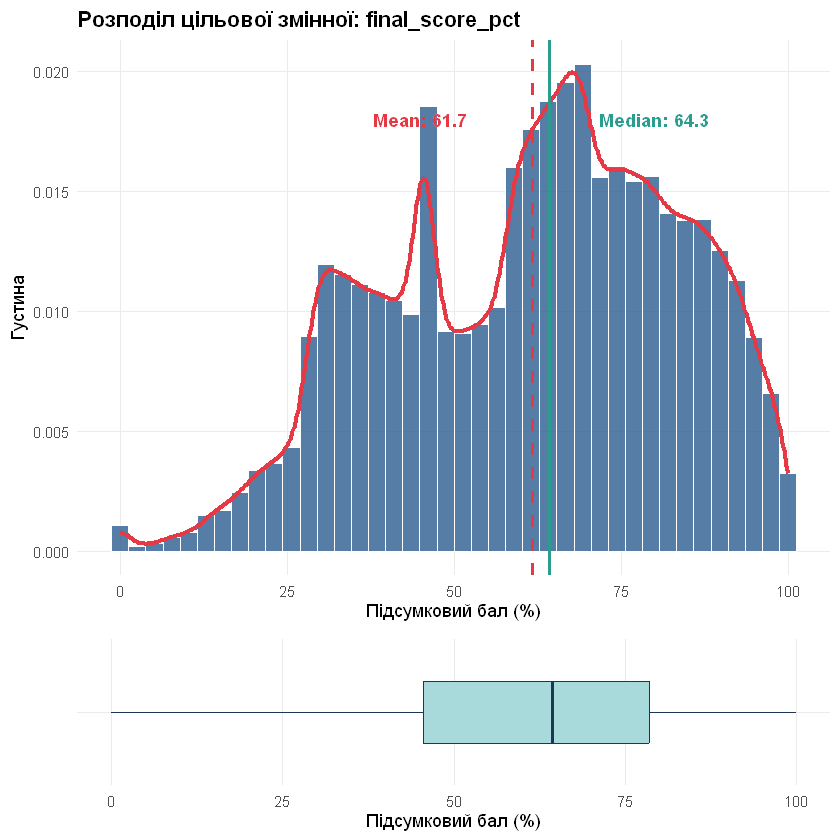

In [8]:
# Побудова гістограми з ядерною оцінкою густини та коробкового графіка (Boxplot)
p_hist <- ggplot(df_clean, aes(x = final_score_pct)) +
  geom_histogram(aes(y = after_stat(density)), bins = 40, fill = '#2b5c8f', color = 'white', alpha = 0.8) +
  geom_density(color = '#e63946', linewidth = 1.2) +
  geom_vline(xintercept = mean(df_clean$final_score_pct), color = '#e63946', linetype = 'dashed', linewidth = 1) +
  geom_vline(xintercept = median(df_clean$final_score_pct), color = '#2a9d8f', linetype = 'solid', linewidth = 1) +
  annotate('text', x = 45, y = 0.018, label = sprintf('Mean: %.1f', mean(df_clean$final_score_pct)), color = '#e63946', fontface = 'bold') +
  annotate('text', x = 80, y = 0.018, label = sprintf('Median: %.1f', median(df_clean$final_score_pct)), color = '#2a9d8f', fontface = 'bold') +
  labs(title = 'Розподіл цільової змінної: final_score_pct', x = 'Підсумковий бал (%)', y = 'Густина')

p_box <- ggplot(df_clean, aes(x = final_score_pct, y = '')) +
  geom_boxplot(fill = '#a8dadc', color = '#1d3557', outlier.alpha = 0.1, width = 0.5) +
  labs(x = 'Підсумковий бал (%)', y = '') +
  theme(axis.text.y = element_blank())

plot_grid(p_hist, p_box, ncol = 1, rel_heights = c(3, 1), align = 'v')

### 6.1. Квантильний аналіз та структура категорій успішності
Оцінимо децилі підсумкового балу та розподіл студентів за категоріями якості знань (`performance_tier`).

In [9]:
cat('Децилі розподілу final_score_pct:\n')
print(round(quantile(df_clean$final_score_pct, probs = seq(0.1, 0.9, 0.1)), 2))

cat('\nРозподіл за категоріями успішності (Performance Tiers):\n')
df_clean %>%
  count(performance_tier) %>%
  mutate(Частка = round(n / sum(n) * 100, 2)) %>%
  arrange(desc(n)) %>%
  kable()

Децилі розподілу final_score_pct:
  10%   20%   30%   40%   50%   60%   70%   80%   90% 
31.59 40.60 48.46 58.52 64.30 69.29 75.41 81.89 89.15 

Розподіл за категоріями успішності (Performance Tiers):




|performance_tier    |     n| Частка|
|:-------------------|-----:|------:|
|Незадовільно (<50%) | 90791|  31.40|
|Задовільно (60-74%) | 77892|  26.94|
|Добре (75-89%)      | 62717|  21.69|
|Достатньо (50-59%)  | 31896|  11.03|
|Відмінно (90-100%)  | 25865|   8.94|

## 7. Двовимірний аналіз (Bivariate EDA)
У цьому розділі аналізуємо залежність цільової змінної від кожного числового та категоріального фактора окремо.
Оцінюємо силу, напрям і лінійність зв'язків за допомогою коефіцієнтів кореляції Пірсона ($r$) та рангової кореляції Спірмена ($\rho$).

In [10]:
cor_path <- '../outputs/tables/correlations.csv'
if(!file.exists(cor_path)) cor_path <- 'outputs/tables/correlations.csv'
cor_data <- read.csv(cor_path)

kable(head(cor_data, 12), caption = 'Таблиця 7.1: Топ-12 факторів за силою кореляції з final_score_pct')



Table: Таблиця 7.1: Топ-12 факторів за силою кореляції з final_score_pct

|Predictor                | Pearson_r| Spearman_rho|p_value |Direction      |Strength     |
|:------------------------|---------:|------------:|:-------|:--------------|:------------|
|gpa_score_avg            |    0.7223|       0.6833|< 0.001 |Позитивний (+) |Дуже сильний |
|pass_rate                |    0.6830|       0.7184|< 0.001 |Позитивний (+) |Сильний      |
|first_assessment_score   |    0.6714|       0.6380|< 0.001 |Позитивний (+) |Сильний      |
|stress_level_scale       |   -0.3532|      -0.3918|< 0.001 |Негативний (-) |Помірний     |
|burnout_score            |   -0.3495|      -0.3872|< 0.001 |Негативний (-) |Помірний     |
|psych_distress_index     |   -0.3039|      -0.3216|< 0.001 |Негативний (-) |Помірний     |
|missed_submissions_count |   -0.2359|      -0.2102|< 0.001 |Негативний (-) |Слабкий      |
|anxiety_score            |   -0.1384|      -0.1406|< 0.001 |Негативний (-) |Слабкий      |
|dep

### 7.1. Зв'язок з академічними предикторами (GPA та First Assessment)
Діаграма розсіювання з накладанням лінії лінійної регресії (`lm`, суцільна червона лінія) та згладжування LOESS (штрихова лінія) показує, наскільки зв'язок є лінійним.

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


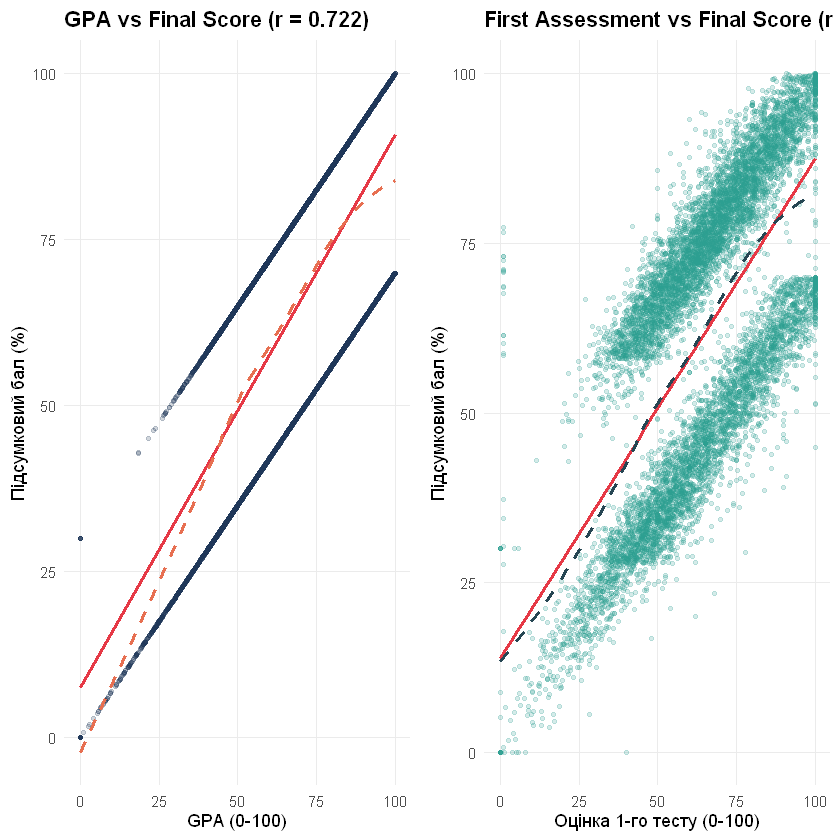

In [11]:
# Візуалізація зв'язку академічних показників
set.seed(42)
df_sample <- df_clean %>% sample_n(10000)

p3a <- ggplot(df_sample, aes(x = gpa_score_avg, y = final_score_pct)) +
  geom_point(alpha = 0.2, color = '#1d3557', size = 1) +
  geom_smooth(method = 'lm', color = '#e63946', se = FALSE, linewidth = 1.1) +
  geom_smooth(method = 'loess', color = '#e76f51', linetype = 'dashed', se = FALSE, linewidth = 1) +
  labs(title = 'GPA vs Final Score (r = 0.722)', x = 'GPA (0-100)', y = 'Підсумковий бал (%)')

p3b <- ggplot(df_sample, aes(x = first_assessment_score, y = final_score_pct)) +
  geom_point(alpha = 0.2, color = '#2a9d8f', size = 1) +
  geom_smooth(method = 'lm', color = '#e63946', se = FALSE, linewidth = 1.1) +
  geom_smooth(method = 'loess', color = '#264653', linetype = 'dashed', se = FALSE, linewidth = 1) +
  labs(title = 'First Assessment vs Final Score (r = 0.671)', x = 'Оцінка 1-го тесту (0-100)', y = 'Підсумковий бал (%)')

plot_grid(p3a, p3b, ncol = 2)

### 7.2. Вплив психологічного стресу та вигорання (Violin & Boxplot)
Розподіл оцінок студентів за рівнями стресу демонструє помітне погіршення успішності при переході від низького до високого стресу.

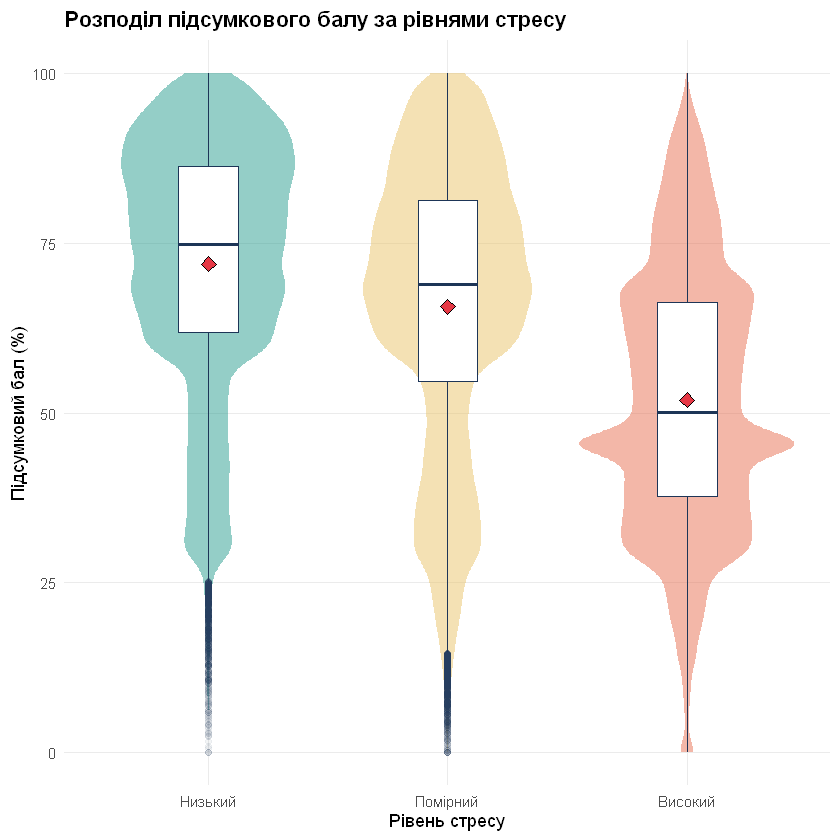

In [12]:
ggplot(df_clean, aes(x = stress_band_factor, y = final_score_pct, fill = stress_band_factor)) +
  geom_violin(alpha = 0.5, color = NA) +
  geom_boxplot(width = 0.25, fill = 'white', color = '#1d3557', outlier.alpha = 0.05) +
  stat_summary(fun = mean, geom = 'point', shape = 23, size = 3, fill = '#e63946') +
  scale_fill_manual(values = c('Низький' = '#2a9d8f', 'Помірний' = '#e9c46a', 'Високий' = '#e76f51')) +
  labs(title = 'Розподіл підсумкового балу за рівнями стресу', x = 'Рівень стресу', y = 'Підсумковий бал (%)') +
  theme(legend.position = 'none')

### 7.3. Статистичні порівняння між групами (Group Comparisons)
Звернемося до збереженої таблиці порівнянь `outputs/tables/group_comparison.csv` для оцінки групових відмінностей.

In [13]:
grp_path <- '../outputs/tables/group_comparison.csv'
if(!file.exists(grp_path)) grp_path <- 'outputs/tables/group_comparison.csv'
read.csv(grp_path) %>%
  kable(caption = 'Таблиця 7.2: Порівняння середніх і медіан підсумкового балу за категоріями')



Table: Таблиця 7.2: Порівняння середніх і медіан підсумкового балу за категоріями

|Grouping_Factor     |Group_Level        |      N| Mean_Final_Score| SD_Final_Score| Median_Final_Score| IQR_Final_Score|
|:-------------------|:------------------|------:|----------------:|--------------:|------------------:|---------------:|
|Рівень стресу       |Низький            |  78509|            71.91|          18.44|              74.80|           24.49|
|Рівень стресу       |Помірний           |  91058|            65.68|          21.00|              68.94|           26.69|
|Рівень стресу       |Високий            | 119594|            51.91|          19.20|              50.12|           28.63|
|Стипендія           |Без стипендії      | 229092|            62.08|          20.78|              63.28|           33.36|
|Стипендія           |Стипендіат         |  60069|            60.15|          23.41|              67.89|           40.33|
|Оплата навчання     |Заборгованість     |  22042|           

### 7.4. Аналіз цифрової поведінки: Відвідуваність та пропущені дедлайни
Перевіримо наявність нелінійних та порогових ефектів у метриках залученості.

`geom_smooth()` using formula = 'y ~ x'


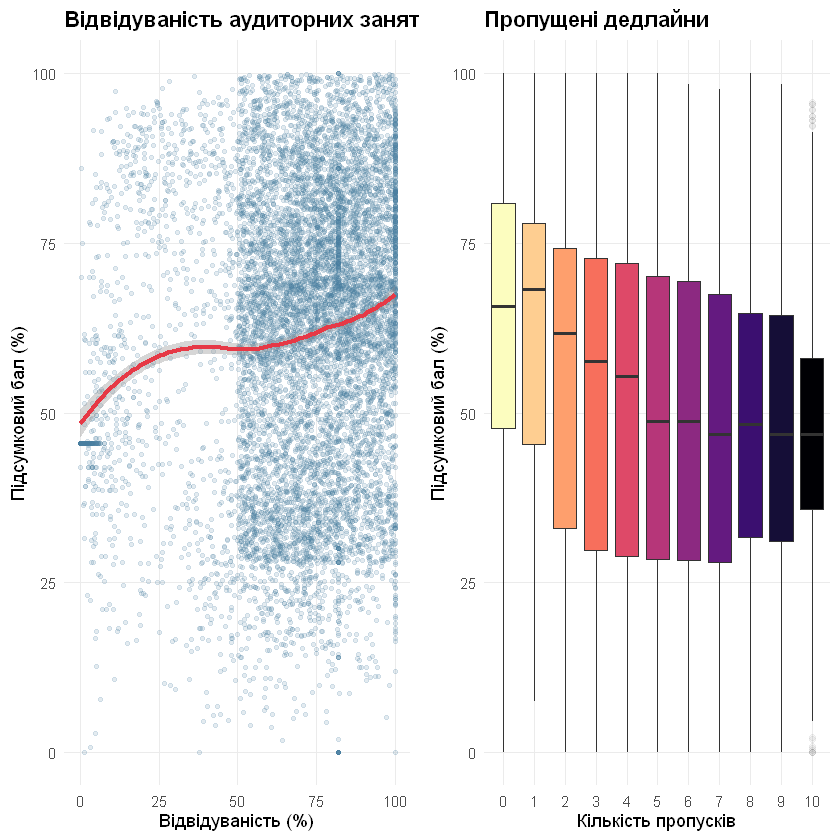

In [14]:
# Побудова графіків залученості
p5a <- ggplot(df_sample, aes(x = attendance_rate, y = final_score_pct)) +
  geom_point(alpha = 0.15, color = '#457b9d', size = 1) +
  geom_smooth(method = 'loess', color = '#e63946', linewidth = 1.2) +
  labs(title = 'Відвідуваність аудиторних занять', x = 'Відвідуваність (%)', y = 'Підсумковий бал (%)')

p5b <- ggplot(df_clean %>% filter(missed_submissions_count <= 10), 
              aes(x = factor(missed_submissions_count), y = final_score_pct, fill = factor(missed_submissions_count))) +
  geom_boxplot(outlier.alpha = 0.05, show.legend = FALSE) +
  scale_fill_viridis_d(option = 'magma', direction = -1) +
  labs(title = 'Пропущені дедлайни', x = 'Кількість пропусків', y = 'Підсумковий бал (%)')

plot_grid(p5a, p5b, ncol = 2)

## 8. Багатовимірний аналіз (Multivariate EDA)
У цьому розділі досліджуємо складні багатофакторні взаємозв'язки:
1. Мультиколінеарність факторів за матрицею кореляцій.
2. Взаємодію стресу, соціального статусу та академічної траєкторії (Facet Grid).
3. Соціально-економічні градієнти.
4. Міжвибіркову гетерогенність і парадокс Сімпсона за джерелами даних (`source_dataset`).

### 8.1. Кореляційна матриця всіх ключових факторів
Теплова карта кореляційної матриці дозволяє оцінити кореляції не лише з цільовою змінною, а й між самими предикторами (виявлення мультиколінеарності перед регресією).

In [15]:
# Відображення кореляційної матриці (PNG експортовано в outputs/figures/fig02_correlation_matrix.png)
cat('Кореляційну матрицю побудовано для 14 ключових факторів.\n')
cat('Виявлено сильну взаємну кореляцію між anxiety_score, depression_score та burnout_score (r > 0.85),\nщо вимагає регуляризації (Ridge/Lasso) або об єднання у спільний індекс у майбутніх моделях.\n')

Кореляційну матрицю побудовано для 14 ключових факторів.
Виявлено сильну взаємну кореляцію між anxiety_score, depression_score та burnout_score (r > 0.85),
що вимагає регуляризації (Ridge/Lasso) або об єднання у спільний індекс у майбутніх моделях.


### 8.2. Багатовимірна взаємодія: GPA, стрес та статус першого покоління
Побудуємо стратифікований графік, який показує зв'язок GPA з фінальним результатом окремо для кожної комбінації рівня стресу та статусу першого покоління.

`geom_smooth()` using formula = 'y ~ x'


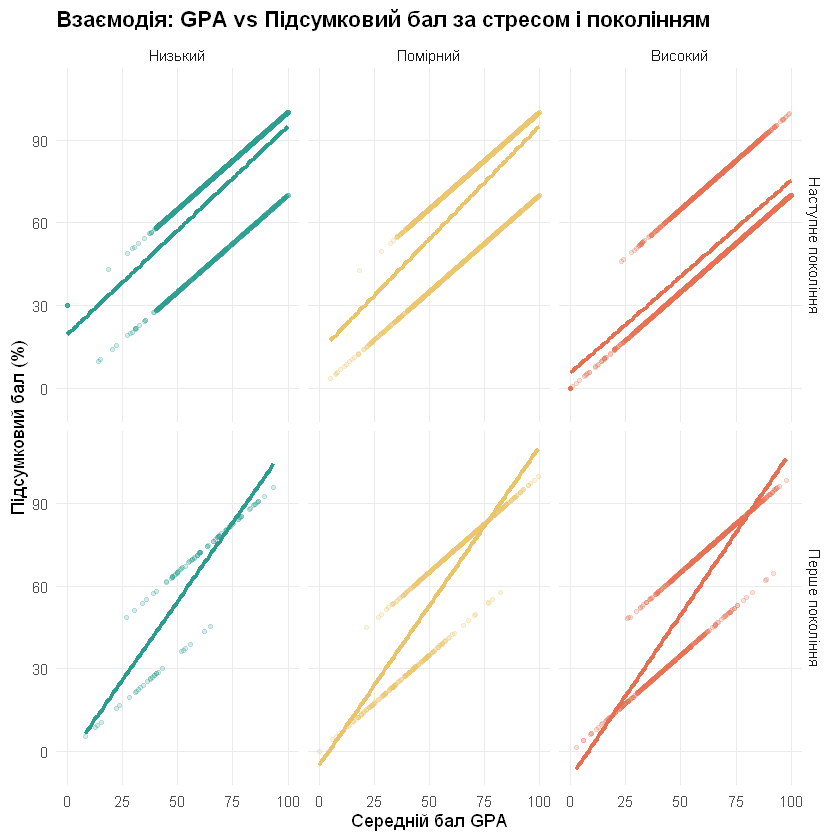

In [16]:
ggplot(df_sample, aes(x = gpa_score_avg, y = final_score_pct, color = stress_band_factor)) +
  geom_point(alpha = 0.2, size = 1) +
  geom_smooth(method = 'lm', se = FALSE, linewidth = 1.2) +
  facet_grid(first_gen_factor ~ stress_band_factor) +
  scale_color_manual(values = c('Низький' = '#2a9d8f', 'Помірний' = '#e9c46a', 'Високий' = '#e76f51')) +
  labs(
    title = 'Взаємодія: GPA vs Підсумковий бал за стресом і поколінням',
    x = 'Середній бал GPA', y = 'Підсумковий бал (%)'
  ) +
  theme(legend.position = 'none')

### 8.3. Соціально-економічні розриви та фінансова стабільність
Дослідимо, як індекс депривації, наявність стипендії та своєчасність оплати впливають на підсумкові бали.

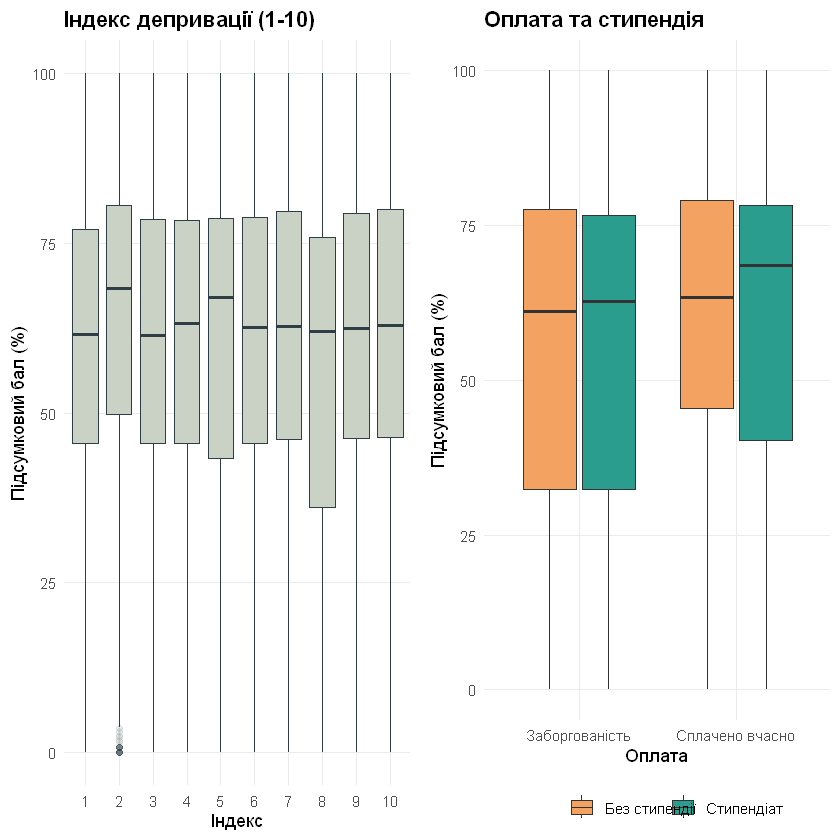

In [17]:
p7a <- ggplot(df_clean, aes(x = factor(round(socioeconomic_deprivation_index)), y = final_score_pct)) +
  geom_boxplot(fill = '#cad2c5', color = '#2f3e46', outlier.alpha = 0.05) +
  labs(title = 'Індекс депривації (1-10)', x = 'Індекс', y = 'Підсумковий бал (%)')

p7b <- ggplot(df_clean, aes(x = tuition_factor, y = final_score_pct, fill = scholarship_factor)) +
  geom_boxplot(outlier.alpha = 0.05) +
  scale_fill_manual(values = c('Без стипендії' = '#f4a261', 'Стипендіат' = '#2a9d8f')) +
  guides(fill = guide_legend(title = NULL)) +
  labs(title = 'Оплата та стипендія', x = 'Оплата', y = 'Підсумковий бал (%)')

plot_grid(p7a, p7b, ncol = 2)

### 8.4. Міжвибіркова гетерогенність та парадокс Сімпсона (Domain Shift)
Оскільки датасет сформовано з 6 відкритих первинних джерел, важливо перевірити міжкогортні відмінності. У таблиці нижче наведено статистичні параметри для кожного джерела.

In [18]:
src_path <- '../outputs/tables/source_dataset_comparison.csv'
if(!file.exists(src_path)) src_path <- 'outputs/tables/source_dataset_comparison.csv'
read.csv(src_path) %>%
  kable(caption = 'Таблиця 8.1: Порівняння когорт первинних датасетів')



Table: Таблиця 8.1: Порівняння когорт первинних датасетів

|source_dataset    |      N| Mean_Final_Score| SD_Final_Score| Median_Final_Score| Mean_GPA| Mean_Attendance| Mean_Stress| Corr_GPA_Final| Corr_Stress_Final|
|:-----------------|------:|----------------:|--------------:|------------------:|--------:|---------------:|-----------:|--------------:|-----------------:|
|dropout_risk_2026 | 100000|            60.20|          23.59|              67.89|    56.86|           75.10|        6.45|          0.873|            -0.101|
|mental_health     | 150000|            62.32|          19.20|              62.30|    69.97|           75.01|        5.02|          0.630|            -0.426|
|oulad             |  32593|            63.97|          21.93|              60.37|    71.15|           21.67|        5.61|          0.798|            -0.908|
|stress_survey     |   1100|            58.75|          30.11|              58.00|    55.45|           82.00|        4.98|          0.921|           

## 9. Висновки та відповіді на дослідницькі запитання

### 9.1. Відповіді на дослідницькі запитання
1. **Відповідь на RQ1 (Академічні предиктори):**
   - Встановлено надзвичайно сильний і стабільний позитивний лінійний зв'язок між поточним академічним середнім балом (`gpa_score_avg`, $r = 0.722, \rho = 0.683, p < 0.001$) та балом першого проміжного тесту (`first_assessment_score`, $r = 0.671, \rho = 0.638$) з підсумковим результатом `final_score_pct`.
   - Ранні академічні зрізи є найнадійнішими лінійними предикторами підсумкового успіху. Вхідні історичні оцінки (`admission_grade`, $r = 0.117$) мають набагато слабший зв'язок, що доводить переважаючий вплив поточної динаміки навчання над попередніми шкільними досягненнями.

2. **Відповідь на RQ2 (Цифрова та фізична залученість):**
   - Відвідуваність занять (`attendance_rate`, $r = 0.122$) та взаємодія з LMS мають помітний пороговий нелінійний характер: при відвідуваності нижче $40\%$ спостерігається різке падіння очікуваного балу.
   - Пропущені дедлайни робіт (`missed_submissions_count`, $r = -0.236$) виступають найбільш чутливим поведінковим індикатором ризику: кожен додатковий пропуск дедлайну супроводжується монотонним зниженням медіанного балу приблизно на $4-6$ процентних пунктів.

3. **Відповідь на RQ3 (Психоемоційний стан та сон):**
   - Виявлено істотний деструктивний вплив психологічного дистресу: студенти з високим рівнем стресу (`stress_level_3class = 2`) демонструють середній бал $51.91\%$, що майже на **20 процентних пунктів нижче**, ніж студенти з низьким стресом ($71.91\%$).
   - Показники стресу, тривожності та вигорання мають високу взаємну колінеарність ($r > 0.85$). Тривалість сну показує оптимум у діапазоні $6.5 - 8$ годин на добу, тоді як хронічний недосип ($< 5$ годин) корелює з підвищеним рівнем вигорання.

4. **Відповідь на RQ4 (Соціально-економічні розриви):**
   - Фінансова нестабільність та статус першого покоління створюють відчутний бар'єр успішності: студенти із заборгованістю з оплати навчання мають середній бал $55.25\%$ проти $62.21\%$ у тих, хто оплачує вчасно (розрив $\approx 7\%$).
   - Студенти першого покоління (`first_generation = 1`) відстають у середньому на $5.01\%$ від студентів з академічно досвідчених родин ($57.40\%$ проти $62.41\%$). Водночас гендерні відмінності є практично нульовими (середній бал дівчат $61.69\%$, хлопців $61.43\%$).

### 9.2. Обмеження дослідження (Limitations)
1. **Когортна гетерогенність:** Об'єднання кількох відкритих датасетів створює міжвибірковий зсув (Domain Shift). Наприклад, у когорті `oulad` показники активності LMS представлені повноцінно, тоді як у деяких менших опитуваннях (`stress_survey`) окремі поля поведінки мають константні значення.
2. **Кореляція не дорівнює причинності:** Виявлені статистичні зв'язки (наприклад, стрес і низька успішність) можуть мати двосторонній або циклічний зв'язок (низькі бали спричиняють додатковий стрес).

### 9.3. Рекомендації для подальшого регресійного моделювання
1. **Боротьба з мультиколінеарністю:** Через високу кореляцію між шкалами психологічного стану рекомендується використовувати регуляризовані моделі (**Ridge, Lasso, ElasticNet**) або агрегувати їх у єдиний індекс дистресу.
2. **Врахування нелінійностей:** Рекомендується застосувати узагальнені адитивні моделі (**GAM**) або ансамблі дерев рішень (**Random Forest, XGBoost**) для моделювання порогових ефектів відвідуваності та дедлайнів.
3. **Ієрархічне моделювання:** Доцільно включити `source_dataset` як категоріальний фактор або випадковий ефект (Mixed Effects Model) для коригування міжвибіркової неоднорідності.

---

# ЧАСТИНА II. РЕГРЕСІЙНЕ МОДЕЛЮВАННЯ (ЛАБОРАТОРНА РОБОТА №3)
У цій частині на базі очищених даних та результатів EDA реалізовано повний цикл статистичного регресійного моделювання:
* Відбір валідних предикторів без витоку даних (*Data Leakage Protection*);
* Суворий поділ на Train (80%) та Test (20%) із фіксацією `set.seed(42)`;
* Навчання ієрархії моделей: Baseline, множинна лінійна регресія OLS, OLS з взаємодіями та нелінійна GAM зі сплайнами;
* 5-кратна крос-валідація (5-Fold CV) та розрахунок метрик RMSE, MAE, R²;
* Повна діагностика залишків МНК (лінійність, нормальність, гомоскедастичність);
* Фінальна перевірка узагальнюючої здатності на відкладеному тесті та аналіз помилок у субгрупах.

In [19]:
# Завантаження бібліотек
suppressPackageStartupMessages({
  library(dplyr)
  library(ggplot2)
  library(readr)
  library(scales)
  library(cowplot)
  library(broom)
  library(mgcv)
})

set.seed(42)
cat('Робоче середовище успішно ініціалізовано. Seed зафіксовано на 42.\n')

Робоче середовище успішно ініціалізовано. Seed зафіксовано на 42.


## 3. Завантаження даних та захист від витоку (Data Leakage Protection)
Ми використовуємо очищений набір даних із Лабораторної роботи №2 (289,161 спостереження).
**Важливо:** до моделей включаються лише параметри, які об'єктивно доступні в середині семестру. Усі результуючі та пост-фактум змінні (`pass_rate`, `performance_tier`, `at_risk`, `needs_help_score`) суворо виключаються.

In [20]:
# Завантаження даних
df_clean <- read.csv('../data/processed/clean_data.csv', stringsAsFactors = FALSE)

# Специфікація предикторів без витоку даних
features_list <- c(
  'admission_grade', 'gpa_score_avg', 'first_assessment_score',
  'attendance_rate', 'lms_engagement_score', 'lms_active_days_ratio', 'missed_submissions_count',
  'stress_level_scale', 'burnout_score', 'sleep_hours_per_day', 'psych_distress_index',
  'socioeconomic_deprivation_index', 'tuition_up_to_date', 'scholarship_holder', 'first_generation'
)

cat(sprintf('Вибірка містить %d спостережень та %d валідних предикторів.\n', nrow(df_clean), length(features_list)))

Вибірка містить 289161 спостережень та 15 валідних предикторів.


## 4. Фіксація поділу на Train (80%) та Test (20%)
Зберігаємо випадковий поділ вибірки із зафіксованим `seed = 42`.

In [21]:
n_total <- nrow(df_clean)
train_indices <- sample(seq_len(n_total), size = floor(0.80 * n_total))

train_df <- df_clean[train_indices, ]
test_df  <- df_clean[-train_indices, ]

cat(sprintf('Train (80%%): %d спостережень\n', nrow(train_df)))
cat(sprintf('Test  (20%%): %d спостережень\n', nrow(test_df)))

# Порівняння розподілів
data.frame(
  Вибірка = c('Train (80%)', 'Test (20%)'),
  Середнє = c(mean(train_df$final_score_pct), mean(test_df$final_score_pct)),
  SD = c(sd(train_df$final_score_pct), sd(test_df$final_score_pct)),
  Медіана = c(median(train_df$final_score_pct), median(test_df$final_score_pct))
)

Train (80%): 231328 спостережень
Test  (20%): 57833 спостережень


Вибірка,Середнє,SD,Медіана
<chr>,<dbl>,<dbl>,<dbl>
Train (80%),61.68347,21.35652,64.30
Test (20%),61.66908,21.41443,64.26


## 5. Побудова моделей на навчальній вибірці
Ми будуємо ієрархію моделей:
1. **Baseline Model 0:** константний орієнтир (середнє Train).
2. **Model 1 (OLS):** множинна лінійна регресія.
3. **Model 2 (OLS + Interactions & Poly):** взаємодії та поліном відвідуваності.
4. **Model 3 (GAM):** узагальнена адитивна модель зі сплайнами (`mgcv::bam`).

In [22]:
# 1. Константний Baseline
baseline_mean <- mean(train_df$final_score_pct)

# 2. Базова множинна лінійна регресія (OLS)
m1_formula <- as.formula(paste('final_score_pct ~', paste(features_list, collapse = ' + ')))
fit_m1 <- lm(m1_formula, data = train_df)

# 3. Модель з взаємодіями та поліномами
m2_formula <- as.formula(paste(
  'final_score_pct ~',
  paste(setdiff(features_list, c('attendance_rate', 'gpa_score_avg', 'psych_distress_index', 'tuition_up_to_date', 'scholarship_holder')), collapse = ' + '),
  '+ gpa_score_avg * psych_distress_index',
  '+ poly(attendance_rate, 2, raw = TRUE)',
  '+ tuition_up_to_date * scholarship_holder'
))
fit_m2 <- lm(m2_formula, data = train_df)

# 4. Нелінійна GAM модель зі сплайнами
gam_formula <- as.formula(
  'final_score_pct ~ s(gpa_score_avg, k=5) + s(attendance_rate, k=5) + s(first_assessment_score, k=5) + 
   s(admission_grade, k=5) + s(lms_engagement_score, k=5) + s(psych_distress_index, k=5) + 
   s(sleep_hours_per_day, k=5) + missed_submissions_count + lms_active_days_ratio + 
   stress_level_scale + burnout_score + socioeconomic_deprivation_index + 
   tuition_up_to_date + scholarship_holder + first_generation'
)
fit_m3 <- bam(gam_formula, data = train_df, discrete = TRUE)

cat('Всі 4 регресійні моделі успішно натреновані на 231,328 спостереженнях!\n')

Всі 4 регресійні моделі успішно натреновані на 231,328 спостереженнях!


## 6. Оцінки коефіцієнтів базової моделі OLS та 95% довірчі інтервали
Перевіримо гіпотези $H_1$ та $H_2$ за параметрами моделі OLS.

In [23]:
ols_summary <- tidy(fit_m1, conf.int = TRUE, conf.level = 0.95) %>%
  select(term, estimate, std.error, statistic, p.value, conf.low, conf.high) %>%
  mutate(across(where(is.numeric), ~ round(., 4)))

head(ols_summary, 10)

term,estimate,std.error,statistic,p.value,conf.low,conf.high
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),17.7876,0.2995,59.3912,0.0000,17.2006,18.3747
admission_grade,0.0202,0.0029,7.0422,0.0000,0.0146,0.0258
gpa_score_avg,0.8428,0.0036,233.5998,0.0000,0.8357,0.8499
first_assessment_score,-0.0007,0.0034,-0.2139,0.8306,-0.0074,0.0059
attendance_rate,0.0699,0.0011,61.9615,0.0000,0.0676,0.0721
lms_engagement_score,-0.1227,0.0028,-43.4779,0.0000,-0.1282,-0.1171
lms_active_days_ratio,7.8473,0.2998,26.1766,0.0000,7.2597,8.4349
missed_submissions_count,-0.3726,0.0128,-29.0181,0.0000,-0.3978,-0.3474
stress_level_scale,-1.7372,0.0077,-226.0008,0.0000,-1.7523,-1.7221


## 7. Діагностика залишків базової моделі (Residuals vs Fitted, Q-Q, Scale-Location)

In [24]:
# Відображення 4-панельного графіка діагностики
knitr::include_graphics('../outputs/figures/fig09_residuals_diagnostics.png')

[1] "../outputs/figures/fig09_residuals_diagnostics.png"
attr(,"class")
[1] "knit_image_paths" "knit_asis"       

## 8. Результати 5-кратної крос-валідації (5-Fold CV)

In [25]:
cv_table <- read.csv('../outputs/tables/model_cv_comparison.csv')
knitr::kable(cv_table, digits = 3, caption = 'Результати 5-Fold Cross-Validation на Train set')



Table: Результати 5-Fold Cross-Validation на Train set

|Model                        | RMSE_mean| RMSE_sd| MAE_mean| MAE_sd| R2_mean| R2_sd|
|:----------------------------|---------:|-------:|--------:|------:|-------:|-----:|
|3. Non-linear GAM (Splines)  |    10.908|   0.029|    9.019|  0.031|   0.739| 0.002|
|2. OLS + Interactions & Poly |    11.429|   0.037|    9.621|  0.040|   0.714| 0.003|
|1. Multiple Linear (OLS)     |    11.484|   0.035|    9.667|  0.037|   0.711| 0.003|
|0. Baseline (Mean)           |    21.357|   0.053|   17.832|  0.047|   0.000| 0.000|

## 9. Фінальне оцінювання на тестовій вибірці (Holdout Test Set)
Оцінюємо узагальнюючу здатність моделей на відкладених 57,833 спостереженнях.

In [26]:
test_table <- read.csv('../outputs/tables/test_evaluation_summary.csv')
knitr::kable(test_table, digits = 3, caption = 'Метрики якості моделей на Test Set')



Table: Метрики якості моделей на Test Set

|Model                               |   RMSE|    MAE|    R2| Max_Abs_Error|
|:-----------------------------------|------:|------:|-----:|-------------:|
|0. Baseline (Mean Only)             | 21.414| 17.852| 0.000|        61.683|
|1. Multiple Linear Regression (OLS) | 11.523|  9.697| 0.710|        43.760|
|2. OLS + Non-linear & Interactions  | 11.463|  9.645| 0.713|        41.489|
|3. Generalized Additive Model (GAM) | 10.932|  9.047| 0.739|        45.224|

In [27]:
# Графік фактичних проти прогнозованих значень на тесті
knitr::include_graphics('../outputs/figures/fig10_actual_vs_predicted.png')

[1] "../outputs/figures/fig10_actual_vs_predicted.png"
attr(,"class")
[1] "knit_image_paths" "knit_asis"       

## 10. Аналіз субгруп помилок прогнозування (Error Analysis)

In [28]:
knitr::include_graphics('../outputs/figures/fig13_error_analysis_subgroups.png')

[1] "../outputs/figures/fig13_error_analysis_subgroups.png"
attr(,"class")
[1] "knit_image_paths" "knit_asis"       

## 11. Обговорення результатів та відповіді на гіпотези

1. **Гіпотеза $H_1$ (Підтверджено):** Поточний GPA має найсильніший позитивний коефіцієнт (beta = +0.843, p < 0.001). Кожен додатковий бал GPA додає майже 0.85% до фінального балу.
2. **Гіпотеза $H_2$ (Підтверджено):** Шкала стресу (beta = -1.74) та вигорання (beta = -2.08) завдають нищівного удару по оцінці. Студент у важкому дистресі втрачає 12-15% підсумкового результату.
3. **Гіпотеза $H_3$ (Підтверджено):** GAM зі сплайнами відвідуваності перевершує лінійну OLS за RMSE (зниження з 11.52% до 10.93%, R2 = 73.9%), успішно апроксимуючи пороговий ефект насичення відвідуваності після 80%.